# Master BigData UCM 2025_26

## Extra noviembre 2026
## Dibujar composición de parlamento español 2023

## Propósito:

En otros módulos he utilizado librerías específicas para dibujar la composición de un parlamento español, ya sea autonómico o el nacional (o "Congreso de los Diputados"). 

Puesto que las elecciones están muy próximas (escribo esto el 17 de noviembre cuando las elecciones se desarrollarán el 29 de noviembre) he creído interesante replicar ese ejercicio con los datos disponibles actualmente, esto es, el resultado de las elecciones de julio 2023.

El ejercicio se basa en plotnine (ggplot) pero existen aplicaciones similares para plotly. Y este ejercicio se basa en una consulta a Gemini (google). Espero que se pueda consultar aquí:

https://share.google/aimode/XYzg3zRFK03ma0cnM


In [1]:
import numpy as np
import pandas as pd
from plotnine import *

## Cargamos los datos directamente del portal datos abiertos de Congreso

Otra vez a partir de una consulta a Gemini

https://share.google/aimode/1299PrxuRKC5LwNGr

con la url https://www.congreso.es/webpublica/opendata/diputados/DiputadosActivos__20261117050005.csv

PERO: la web del congreso no permite consulta directa. Debemos descargar el csv a nuestro sistema y leer desde ahí

OJO!!! Ese .csv presenta la composición de la **Diputación Permanente del Congreso** porque las Cortes se han disuelto. Hay que consultar otro .csv, este:

https://www.congreso.es/webpublica/opendata/diputados/odsDiputados14__20261117050130.csv

In [2]:
# Sustituye esta URL por el enlace directo al archivo CSV o JSON de "Diputados en Activo"
donde_esta_csv = "/home/pedro/Descargas/odsDiputados14__20261117050130.csv"

# Cargar en DataFrame (los CSV del Congreso suelen usar ';' o ',' como separador)
df = pd.read_csv(donde_esta_csv, sep=";", encoding="utf-8")

# Ver las primeras filas y el reparto actual por Grupo Parlamentario
print(df.head())
print(df["FORMACIONELECTORAL"].value_counts())

                              NOMBRE    CIRCUNSCRIPCION FORMACIONELECTORAL  \
0             Ábalos Meco, José Luis  Valencia/València               PSOE   
1            Abascal Conde, Santiago             Madrid                Vox   
2          Aceves Galindo, José Luis            Segovia               PSOE   
3  Agirretxea Urresti, Joseba Andoni           Gipuzkoa            EAJ-PNV   
4          Aizcorbe Torra, Juan José          Barcelona                Vox   

  FECHACONDICIONPLENA   FECHAALTA   FECHABAJA  \
0          03/12/2019  27/11/2019  17/08/2023   
1          03/12/2019  20/11/2019  17/08/2023   
2          03/12/2019  20/11/2019  30/05/2023   
3          03/12/2019  21/11/2019  30/05/2023   
4          03/12/2019  25/11/2019  17/08/2023   

                    GRUPOPARLAMENTARIO FECHAALTAENGRUPOPARLAMENTARIO  \
0       Grupo Parlamentario Socialista                    04/12/2019   
1              Grupo Parlamentario VOX                    04/12/2019   
2       Grupo Parlam

In [3]:
print(df.tail())

                                NOMBRE CIRCUNSCRIPCION FORMACIONELECTORAL  \
408           Zamarrón Moreno, Agustín          Burgos               PSOE   
409  Zambrano García-Raez, Carlos José           Cádiz                Vox   
410              Zapata Simón, Aurelio     Guadalajara               PSOE   
411              Zaragoza Alonso, José       Barcelona           PSC-PSOE   
412         Zurita Expósito, Ana María    S/C Tenerife                 PP   

    FECHACONDICIONPLENA   FECHAALTA   FECHABAJA  \
408          03/12/2019  19/11/2019  30/05/2023   
409          03/12/2019  27/11/2019  30/05/2023   
410          26/10/2022  25/10/2022  30/05/2023   
411          03/12/2019  26/11/2019  17/08/2023   
412          03/12/2019  21/11/2019  30/05/2023   

                             GRUPOPARLAMENTARIO FECHAALTAENGRUPOPARLAMENTARIO  \
408              Grupo Parlamentario Socialista                    04/12/2019   
409                     Grupo Parlamentario VOX                    0

Nada, imposible, estos datos no son correctos. Para que veamos que parece que no se quiere facilitar este ejercicio.

Probemos otra alternativa:

https://congresoabierto.org/datos/?paso=1&tabla=diputados

In [4]:
# Sustituye esta URL por el enlace directo al archivo CSV o JSON de "Diputados en Activo"
donde_esta_csv = "/home/pedro/Descargas/congreso-abierto-diputados.csv"

# Cargar en DataFrame (los CSV del Congreso suelen usar ';' o ',' como separador)
df = pd.read_csv(donde_esta_csv, sep=";", encoding="utf-8")

# Ver las primeras filas y el reparto actual por Grupo Parlamentario
print(df.head())
print(df["Grupo"].value_counts())

      Nombre        Apellidos Grupo Circunscripción Retribución mensual (€)  \
0   Cristina  Abades Martínez    PP            Lugo                 6781,88   
1   Santiago    Abascal Conde   VOX          Madrid                 4399,37   
2      Sofía      Acedo Reyes    PP         Melilla                 6781,88   
3  José Luis   Aceves Galindo  PSOE         Segovia                 6781,88   
4      María   Adrio Taracido  PSOE      Pontevedra                 6781,88   

   Propiedades  Viviendas Lectura no confirmada  
0          3.0        1.0                    No  
1          1.0        1.0                    Sí  
2          1.0        1.0                    No  
3          2.0        2.0                    No  
4          5.0        3.0                    No  
Grupo
PP          137
PSOE        121
VOX          32
SUMAR        26
Mixto         9
ERC           7
Junts         7
EH Bildu      6
PNV           5
Name: count, dtype: int64


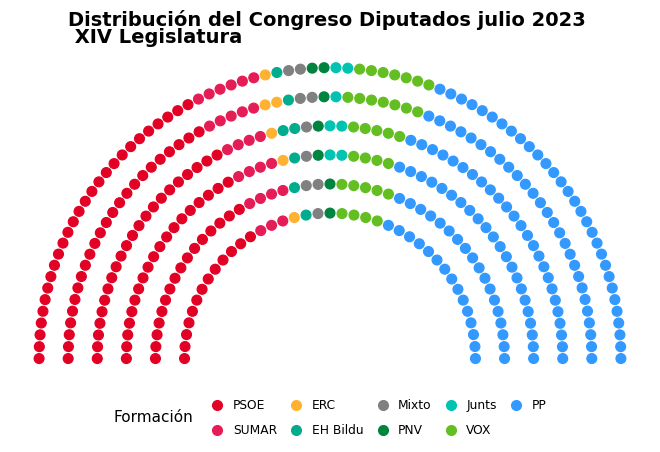

In [5]:
# 1. Preparamos los datos con el orden aproximado de posición en el hemiciclo a partir de datos mostrados antes

# OJO OJO ORDEN INVERSO, PORQUE LOS PRIMEROS SALEN A LA IZQUIERDA

partidos = ['PSOE',
            'SUMAR',
            'ERC',
            'EH Bildu',
            'Mixto',
            'PNV',
            'Junts', 
            'VOX', 
            'PP'                
           ]
escanos = [121, 26, 6, 7, 9, 7, 7, 32, 137]
colores = {'PP': '#3399FF', 
           'VOX': '#63BE21', 
           'Junts': '#00C3B2', 
           'PNV': '#00833E',
           'Mixto': '#808080',
           'ERC': '#FFB232',
           'EH Bildu': '#00AC8E',
           'SUMAR': '#E51C55',
           'PSOE': '#E20025'
          }

# 2. Generar coordenadas (x, y) en formato hemiciclo (similar a ggparliament)
total_escanos = sum(escanos)
filas = 6
radios = np.linspace(1.5, 3.0, filas)
asientos_por_fila = np.round(radios / radios.sum() * total_escanos).astype(int)
asientos_por_fila[-1] += total_escanos - asientos_por_fila.sum()

coordenadas = []
for r, n_asientos in zip(radios, asientos_por_fila):
    angulos = np.linspace(np.pi, 0, n_asientos)
    for angulo in angulos:
        coordenadas.append({'x': r * np.cos(angulo), 'y': r * np.sin(angulo), 'angulo': angulo})

# Ordenar de izquierda a derecha y asignar partidos
df = pd.DataFrame(coordenadas).sort_values(by=['angulo', 'x'], ascending=[False, True])
lista_partidos = [p for p, count in zip(partidos, escanos) for _ in range(count)]
df['partido'] = pd.Categorical(lista_partidos, categories=partidos, ordered=True)

# 3. Construir el gráfico con sintaxis ggplot (Plotnine)
grafico = (
    ggplot(df, aes(x='x', y='y', color='partido'))
    + geom_point(size=3.5)
    + scale_color_manual(values=colores)
    + coord_fixed()
    + theme_void()
    + labs(title='Distribución del Congreso Diputados julio 2023 \n XIV Legislatura', color='Formación')
    + theme(
        legend_position='bottom',
        plot_title=element_text(hjust=0.5, size=14, weight='bold')
    )
)

grafico.draw()

## Añadimos una línea vertical de la mayoría absoluta

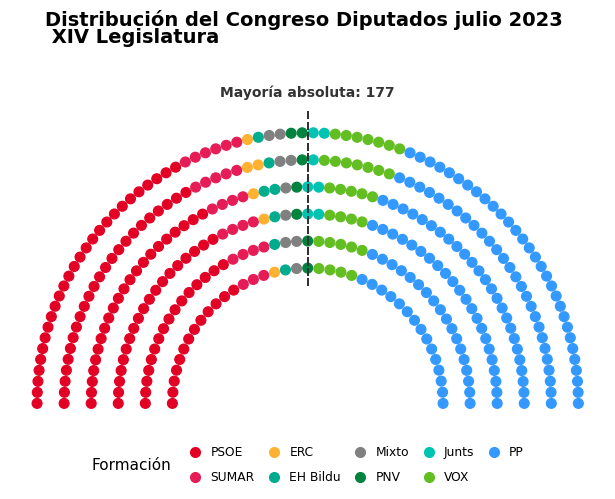

In [6]:
# 2. Calcular mayoría absoluta y coordenadas
total_escanos = sum(escanos)
mayoria_absoluta = (total_escanos // 2) + 1

filas = 6
radios = np.linspace(1.5, 3.0, filas)
asientos_por_fila = np.round(radios / radios.sum() * total_escanos).astype(int)
asientos_por_fila[-1] += total_escanos - asientos_por_fila.sum()

coordenadas = []
for r, n_asientos in zip(radios, asientos_por_fila):
    angulos = np.linspace(np.pi, 0, n_asientos)
    for angulo in angulos:
        coordenadas.append({'x': r * np.cos(angulo), 'y': r * np.sin(angulo), 'angulo': angulo})

df = pd.DataFrame(coordenadas).sort_values(by=['angulo', 'x'], ascending=[False, True])
lista_partidos = [p for p, count in zip(partidos, escanos) for _ in range(count)]
df['partido'] = pd.Categorical(lista_partidos, categories=partidos, ordered=True)

# 3. Gráfico con línea de mayoría absoluta
grafico = (
    ggplot(df, aes(x='x', y='y', color='partido'))
    + geom_point(size=3.5)
    # Línea vertical discontinua en el centro (x=0)
    + geom_segment(
        aes(x=0, xend=0, y=1.3, yend=3.25),
        color='#333333',
        linetype='dashed',
        size=0.8
    )
    # Etiqueta superior de mayoría absoluta
    + annotate(
        'text',
        x=0,
        y=3.45,
        label=f'Mayoría absoluta: {mayoria_absoluta}',
        size=10,
        color='#333333',
        fontweight='bold'
    )
    + scale_color_manual(values=colores)
    + coord_fixed(ylim=(0, 3.7)) # Ampliamos el límite Y superior para que quepa el texto
    + theme_void()
    + labs(title='Distribución del Congreso Diputados julio 2023 \n XIV Legislatura', color='Formación')
    + theme(
        legend_position='bottom',
        plot_title=element_text(hjust=0.5, size=14, weight='bold')
    )
)

grafico.draw()